# Tuning thresholds

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Tuning thresholds, comparing model variants and exporting results
</div>
<!-- markdownlint-enable MD033 -->

---

You can now read every piece of a {term}`ChangeStar` result. This page covers the decisions that shape what ends up in `change_map` in the first place, the threshold and the model variant, compares the result with a simple pixel-wise baseline, and finishes by getting the changes into a GIS-ready file.

---

## 1. Motivation

`s1_s1c1_vitb` and a threshold of 0.5 are defaults, not guaranteed to be the right choice for every project. Knowing how to adjust sensitivity, how to compare variants, and how to check whether a deep learning model actually beats a simple baseline is what turns this lesson's example into a workflow you can adapt to your own study area. Exporting the result as clean, attributed polygons is what makes it usable outside this notebook.

---

## 2. Core idea

Two independent choices shape ChangeStar's output: which pretrained model variant you use, and which {term}`probability threshold <Probability Threshold>` converts the continuous change probability into a binary map. Both are worth testing explicitly rather than accepting defaults. A pixel-wise baseline on the same images tells you how much the deep learning model actually adds. Once you trust a result, converting it to polygons with useful attributes is what makes it usable in a GIS.

---

## 3. Workflow

### A. Reload the result

In [1]:
import logging
import os
import warnings
from pathlib import Path

os.environ["HF_HUB_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")
for name in ["httpx", "huggingface_hub", "pyogrio", "numexpr", "rasterio"]:
    logging.getLogger(name).setLevel(logging.ERROR)

import geoai
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from rasterio.features import shapes
from shapely.geometry import shape
from skimage.filters import threshold_otsu
from geoai.change_detection import ChangeStarDetection

RGB_DIR = Path("data/processed")
OUT_DIR = Path("changestar_results")
rgb_paths = {year: RGB_DIR / f"vexcel_osaka_{year}_rgb.tif" for year in [2022, 2025]}
PIXEL_AREA_M2 = 0.2 * 0.2
device = geoai.get_device()

result = dict(np.load(OUT_DIR / "changestar_s1_result.npz"))

images = {}
for year, path in rgb_paths.items():
    with rasterio.open(path) as src:
        images[year] = np.moveaxis(src.read(), 0, -1)
        transform, crs = src.transform, src.crs
print("Loaded the saved S1 result and both RGB images.")

Loaded the saved S1 result and both RGB images.


As on the previous page, we load the saved result instead of running the model again. If the file is missing, run the ChangeStar workflow page first.

### B. Adjusting the detection threshold

`predict()` has a `threshold` argument, but you do not need to run the model again to try different values: the change map is simply `change_prob > threshold`. Thresholding the saved probabilities directly gives the same result in a fraction of a second.

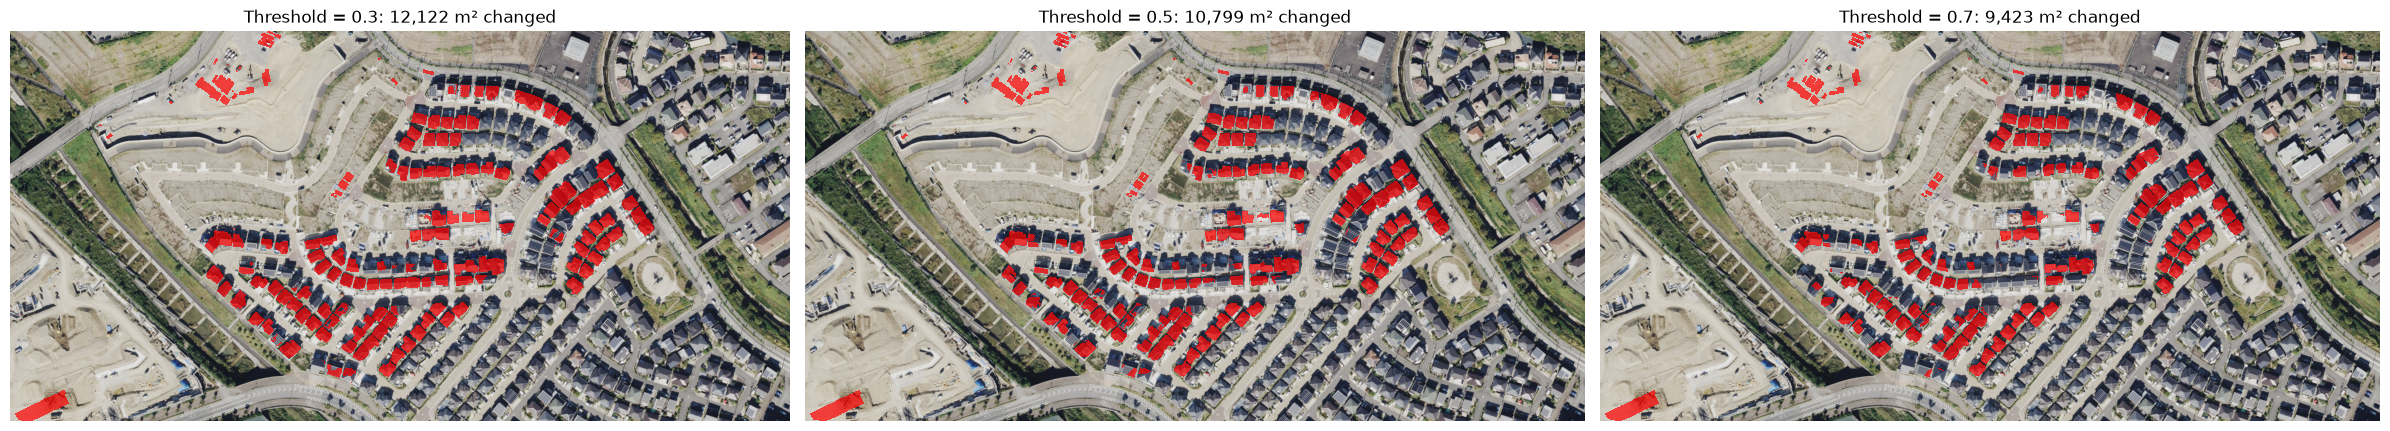

In [2]:
prob = result["change_prob"]
assert np.array_equal(prob > 0.5, result["change_map"] == 1)  # the default map, reproduced

thresholds = [0.3, 0.5, 0.7]
fig, axes = plt.subplots(1, len(thresholds), figsize=(24, 4.5))
for ax, thresh in zip(axes, thresholds):
    change = prob > thresh
    ax.imshow(images[2025])
    ax.imshow(np.ma.masked_equal(change, 0), cmap="autumn", alpha=0.7, interpolation="nearest")
    ax.set_title(f"Threshold = {thresh}: {change.sum() * PIXEL_AREA_M2:,.0f} m² changed")
    ax.axis("off")
plt.tight_layout()
plt.show()

Lowering the threshold increases sensitivity: more pixels with moderate change probability count as changed, which recovers some of the partially missed houses from the previous page, but can also add false alarms. Raising it increases specificity: only high-confidence changes remain, at the cost of missing subtler ones. This is the same trade-off you tuned with `confidence_threshold` in L06's detection workflow, applied here to change probability instead.

To see how sensitive the result is overall, plot the changed area against the threshold:

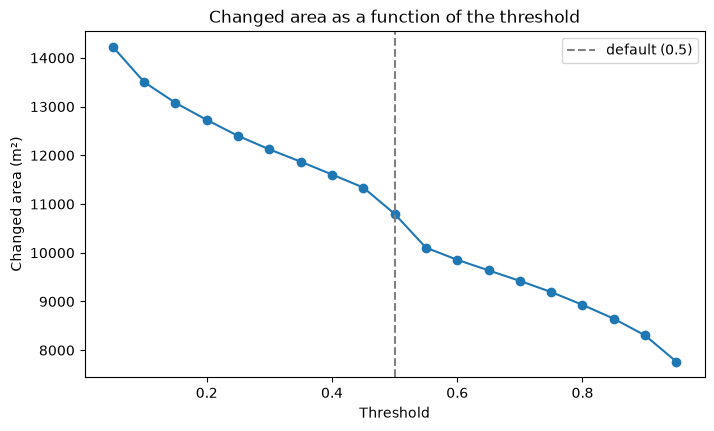

Changed area at 0.3: 12,122 m², at 0.5: 10,799 m², at 0.7: 9,423 m²


In [3]:
grid = np.linspace(0.05, 0.95, 19)
areas = [(prob > t).sum() * PIXEL_AREA_M2 for t in grid]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(grid, areas, marker="o")
ax.axvline(0.5, color="grey", linestyle="--", label="default (0.5)")
ax.set_xlabel("Threshold")
ax.set_ylabel("Changed area (m²)")
ax.set_title("Changed area as a function of the threshold")
ax.legend()
plt.show()

print(f"Changed area at 0.3: {areas[5]:,.0f} m², at 0.5: {areas[9]:,.0f} m², at 0.7: {areas[13]:,.0f} m²")

The curve declines steadily, without a cliff: moving the threshold from 0.3 to 0.7 reduces the changed area by a little over a fifth. The small step right at 0.5 is the peak of tile-averaged probabilities from the previous page. Because most probabilities sit close to 0 or 1, even extreme thresholds do not double or halve the result, but a statement such as "about 10,800 m² changed" clearly depends on the threshold. Report the value you used, or a range. Without labeled data, as here, this curve and a visual check are what you have. With labeled data, you can tune the threshold quantitatively, as page 8 of this lesson does.

### C. Comparing model variants

2026-11-15 21:31:37, INFO:EVER:Load Changen2 pre-trained weight from EVER-Z/Changen2-ChangeStar1x256/s9c1_cstar_vitb_1x256.pth


2026-11-15 21:31:37, INFO:EVER:architecture: changestar_1x256 | backbone: vitb | modeling type: s9c1 | pre-trained data: Changen2-S9-27k | finetuned on: None


S1 changed area:   10,799 m²
S9 changed area:   34,846 m²
Flagged by both:    6,415 m²


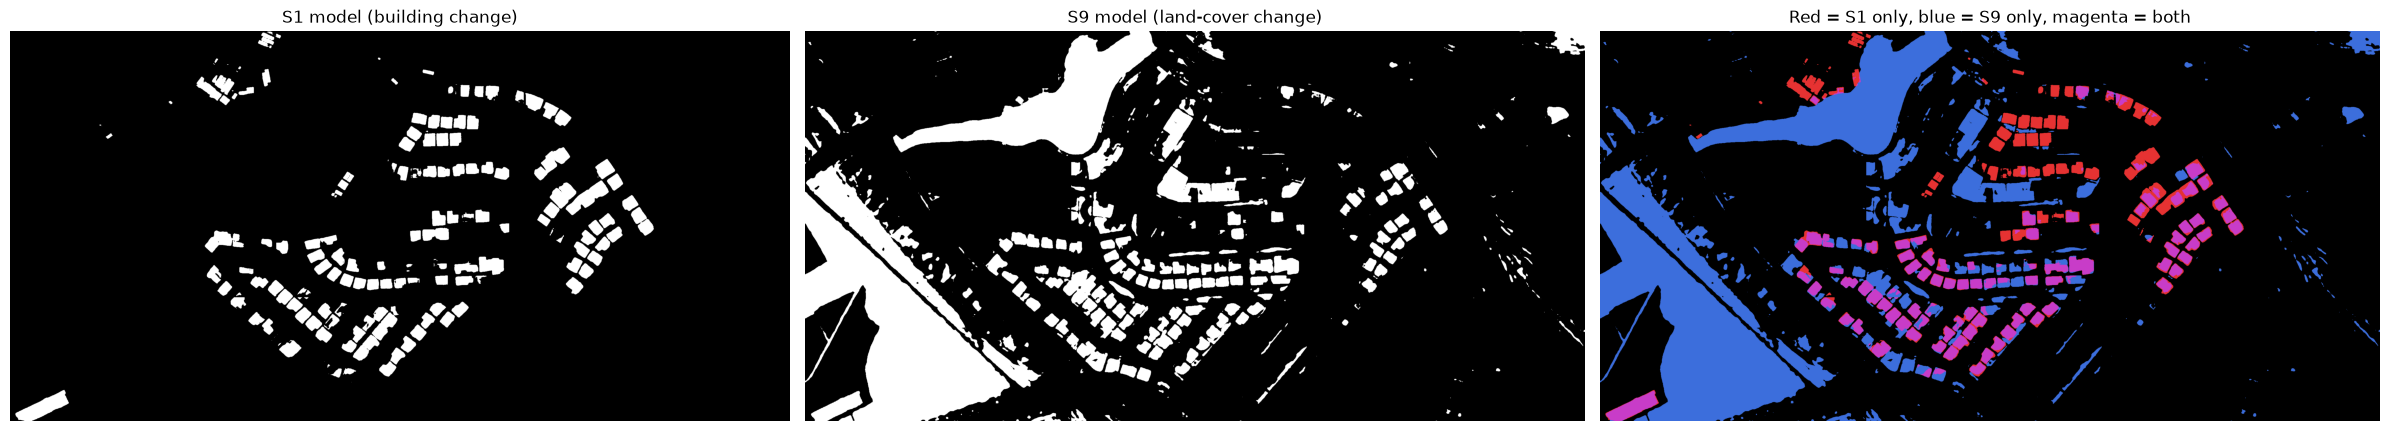

In [4]:
detector_s9 = ChangeStarDetection(model_name="s9_s9c1_vitb", device=device)
result_s9 = detector_s9.predict(str(rgb_paths[2022]), str(rgb_paths[2025]))

s1, s9 = result["change_map"] == 1, result_s9["change_map"] == 1
print(f"S1 changed area: {s1.sum() * PIXEL_AREA_M2:8,.0f} m²")
print(f"S9 changed area: {s9.sum() * PIXEL_AREA_M2:8,.0f} m²")
print(f"Flagged by both: {(s1 & s9).sum() * PIXEL_AREA_M2:8,.0f} m²")

combined = np.zeros((*s1.shape, 3), dtype=np.uint8)
combined[s1 & ~s9] = [230, 50, 50]   # S1 only: red
combined[s9 & ~s1] = [60, 110, 220]  # S9 only: blue
combined[s1 & s9] = [200, 60, 200]   # both: magenta

fig, axes = plt.subplots(1, 3, figsize=(24, 4.5))
axes[0].imshow(s1, cmap="gray")
axes[0].set_title("S1 model (building change)")
axes[1].imshow(s9, cmap="gray")
axes[1].set_title("S9 model (land-cover change)")
axes[2].imshow(combined)
axes[2].set_title("Red = S1 only, blue = S9 only, magenta = both")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

The two variants disagree substantially, and the reason is in their names. `s1_s1c1` was pretrained on synthetic *building* change and segments one class. `s9_s9c1` was pretrained on synthetic *land-cover* change and segments nine classes, so it flags any land-cover transition. The large blue areas show this: the wooded slope next to the car park in the upper left was cleared, the grassland in the bottom left became a construction site, and vegetation grew along the embankment on the left. These are real changes, just not building changes, so they are not simply errors; they answer a different question. Only about 60% of the S1 change area is also flagged by S9 (magenta), and the two models disagree about some of the houses themselves (red), a reminder that both are fallible.

The S9 variant's per-date maps show what it "sees":

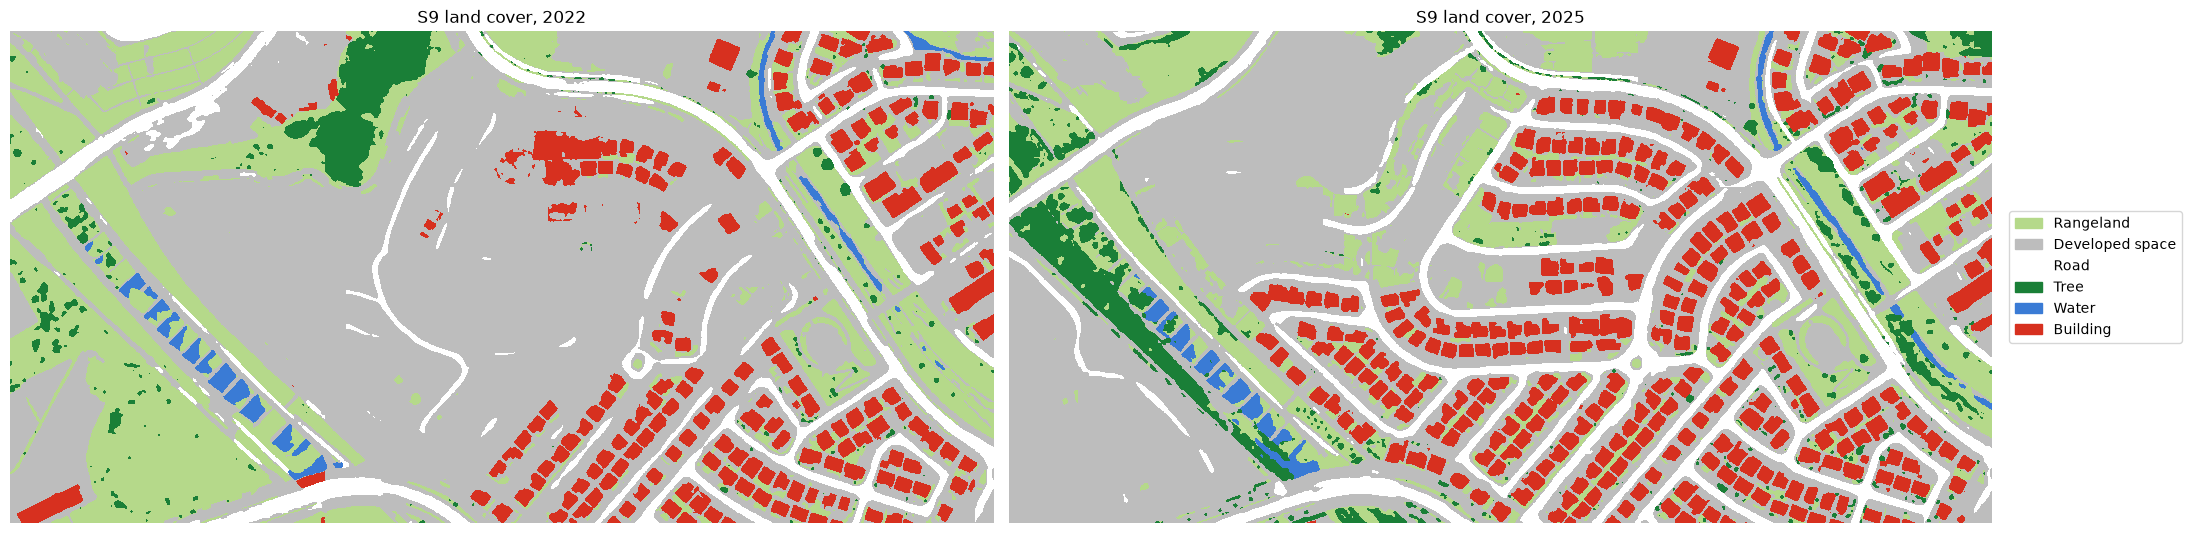

In [5]:
s9_names = ["Background", "Bareland", "Rangeland", "Developed space", "Road",
            "Tree", "Water", "Agriculture land", "Building"]
s9_colours = ["#000000", "#c8a46b", "#b5d98a", "#bdbdbd", "#ffffff",
              "#1a7f37", "#3a7bd5", "#f2d24b", "#d7301f"]
s9_cmap = ListedColormap(s9_colours)
present = np.union1d(np.unique(result_s9["t1_semantic"]), np.unique(result_s9["t2_semantic"]))

fig, axes = plt.subplots(1, 2, figsize=(22, 5.5))
for ax, key, year in zip(axes, ["t1_semantic", "t2_semantic"], [2022, 2025]):
    ax.imshow(result_s9[key], cmap=s9_cmap, vmin=0, vmax=8, interpolation="nearest")
    ax.set_title(f"S9 land cover, {year}")
    ax.axis("off")
axes[1].legend(
    handles=[Patch(color=s9_colours[i], label=s9_names[i]) for i in present],
    loc="center left", bbox_to_anchor=(1.01, 0.5),
)
plt.tight_layout()
plt.show()

The nine classes follow the OpenEarthMap land-cover scheme used to generate the S9 training data; the legend lists only the classes that occur here. The maps show both the model's strength and its limits. It captures the new streets and rows of buildings and the cleared woodland convincingly. But it labels the bare 2022 construction site almost entirely as "developed space", not as "bareland", so a land-cover class can describe a surface quite differently from how you would. Choose the variant by your question: for counting new buildings, S1; for describing how the land surface as a whole changed, S9. In both cases, compare at least one alternative before committing.

### D. Better than a simple baseline?

Page 3 used pixel-wise methods on Sentinel-2. Applying the same idea to this image pair shows directly what ChangeStar adds.

Baseline (RGB difference, Otsu threshold):   51,526 m² changed
ChangeStar S1 (threshold 0.5):               10,799 m² changed


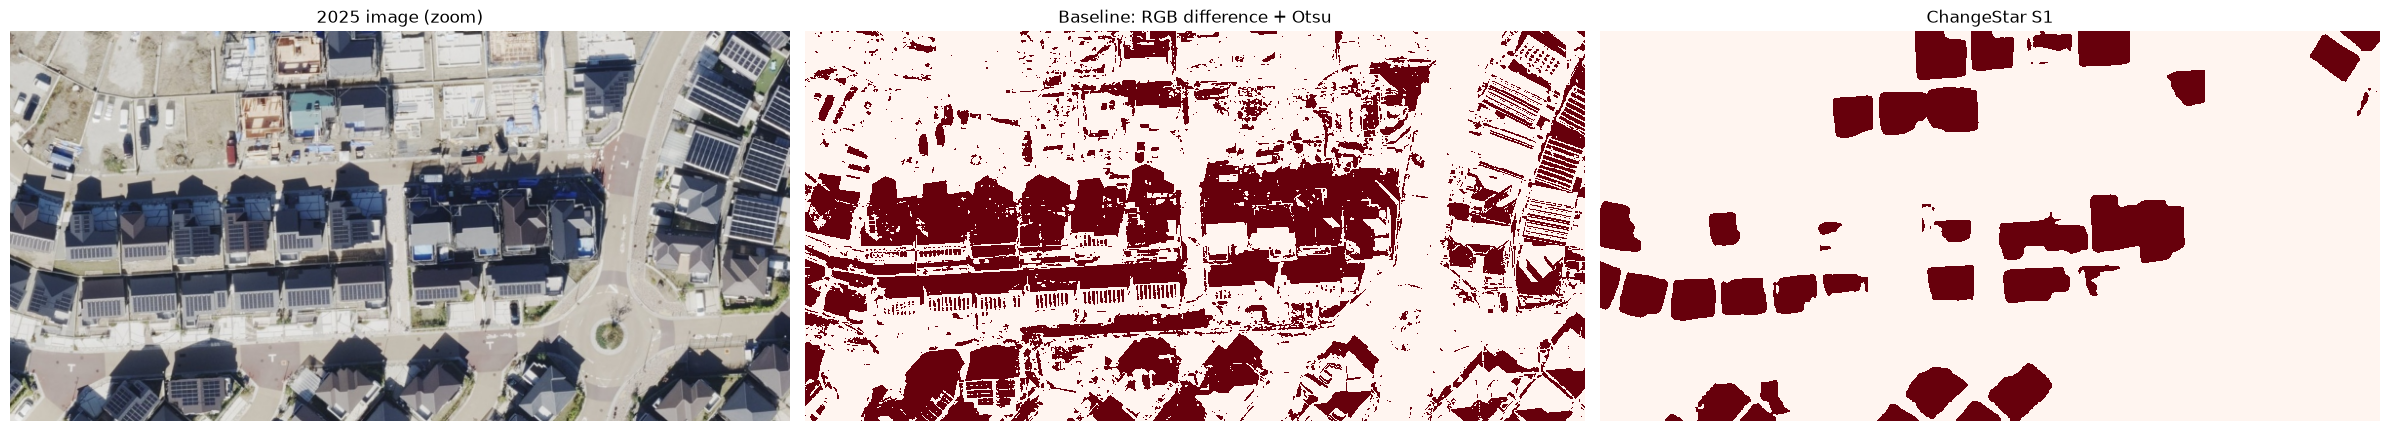

In [6]:
a = images[2022].astype(np.float32)
b = images[2025].astype(np.float32)
magnitude = np.sqrt(((b - a) ** 2).sum(axis=2))  # length of the RGB change vector per pixel

baseline = magnitude > threshold_otsu(magnitude)
print(f"Baseline (RGB difference, Otsu threshold): {baseline.sum() * PIXEL_AREA_M2:8,.0f} m² changed")
print(f"ChangeStar S1 (threshold 0.5):             {s1.sum() * PIXEL_AREA_M2:8,.0f} m² changed")

rows, cols = slice(700, 1100), slice(1300, 2100)  # a window with new and existing houses
fig, axes = plt.subplots(1, 3, figsize=(24, 5))
axes[0].imshow(images[2025][rows, cols])
axes[0].set_title("2025 image (zoom)")
axes[1].imshow(baseline[rows, cols], cmap="Reds", interpolation="nearest")
axes[1].set_title("Baseline: RGB difference + Otsu")
axes[2].imshow(s1[rows, cols], cmap="Reds", interpolation="nearest")
axes[2].set_title("ChangeStar S1")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

The baseline flags far more area, and the zoom shows why. It reacts to *every* pixel whose colour changed: new houses, but also new paving, vegetation that grew, cars that moved, and shadows that fall differently, and it does so pixel by pixel, producing ragged, speckled shapes. ChangeStar returns compact, house-shaped objects because it uses spatial context and has learned what a building looks like. This is the advantage of siamese deep learning models described on page 4, now visible on real data. It also explains the limits: ChangeStar only finds the kind of change it was trained for, while the baseline, for all its noise, makes no such assumption.

### E. From pixels to GIS-ready polygons

`predict()` already saved {term}`GeoTIFFs <GeoTIFF>` and a {term}`GeoPackage` on the workflow page:

In [7]:
for f in sorted(OUT_DIR.iterdir()):
    print(f"{f.name:30s} {f.stat().st_size / 1024 / 1024:6.2f} MB")

building_changes.gpkg            0.48 MB
change_map.tif                   0.12 MB
changes.gpkg                     0.50 MB
changestar_s1_result.npz        47.73 MB
t1_buildings.tif                 0.13 MB
t2_buildings.tif                 0.15 MB


The saved `changes.gpkg` contains one polygon per connected patch of changed pixels, but no information about *what* changed, and many polygons are tiny fragments:

In [8]:
changes = gpd.read_file(OUT_DIR / "changes.gpkg")
changes["area_m2"] = changes.area
print(f"{len(changes)} polygons, columns: {list(changes.columns)}")
print(changes["area_m2"].describe().round(1))
print(f"Polygons smaller than 10 m²: {(changes['area_m2'] < 10).sum()}")

179 polygons, columns: ['change', 'geometry', 'area_m2']
count    179.0
mean      60.3
std       69.5
min        0.0
25%        3.0
50%       60.6
75%       86.1
max      431.7
Name: area_m2, dtype: float64
Polygons smaller than 10 m²: 58


The area comes from the polygons' geometry, which is in metres because the {term}`CRS <Coordinate Reference System>` ({abbr}`EPSG (European Petroleum Survey Group, the registry that numbers coordinate reference systems)`:6674, a Japanese plane rectangular system) is projected. A typical detached house covers roughly 50 to 100 m², so polygons of a few square metres are fragments: edge pieces, vehicles, or noise.

A more useful product combines the change map with the from–to information from the previous page, and drops the fragments:

In [9]:
t1, t2 = result["t1_semantic"], result["t2_semantic"]
change_type = np.zeros(t1.shape, dtype=np.uint8)
change_type[(result["change_map"] == 1) & (t2 == 1) & (t1 == 0)] = 1  # new building
change_type[(result["change_map"] == 1) & (t1 == 1) & (t2 == 0)] = 2  # removed building

type_names = {1: "new building", 2: "removed building"}
records = [
    {"change_type": type_names[int(value)], "geometry": shape(geom)}
    for geom, value in shapes(change_type, mask=change_type > 0, transform=transform)
]
building_changes = gpd.GeoDataFrame(records, crs=crs)
building_changes["area_m2"] = building_changes.area.round(1)

MIN_AREA_M2 = 10
building_changes = building_changes[building_changes["area_m2"] >= MIN_AREA_M2].reset_index(drop=True)
building_changes.to_file(OUT_DIR / "building_changes.gpkg", driver="GPKG")

print(building_changes.groupby("change_type")["area_m2"].agg(["count", "sum", "median"]).round(0))

                  count     sum  median
change_type                            
new building        113  9519.0    82.0
removed building     14  1066.0    38.0


`rasterio.features.shapes()` traces the outlines of connected groups of pixels with the same value and returns them as geometries in the raster's coordinates, the same {term}`vectorization <Vectorization>` step used in L08. Each polygon now carries a `change_type` and an `area_m2` attribute, and fragments below 10 m² are removed. The minimum area is a project decision: it should be smaller than the smallest change you care about. The median new building polygon, about 80 m², matches the size of a detached house. Area filtering cannot fix every error, though: the "removed building" polygons still include the parked vehicles from the previous page, which only a check against the imagery reveals.

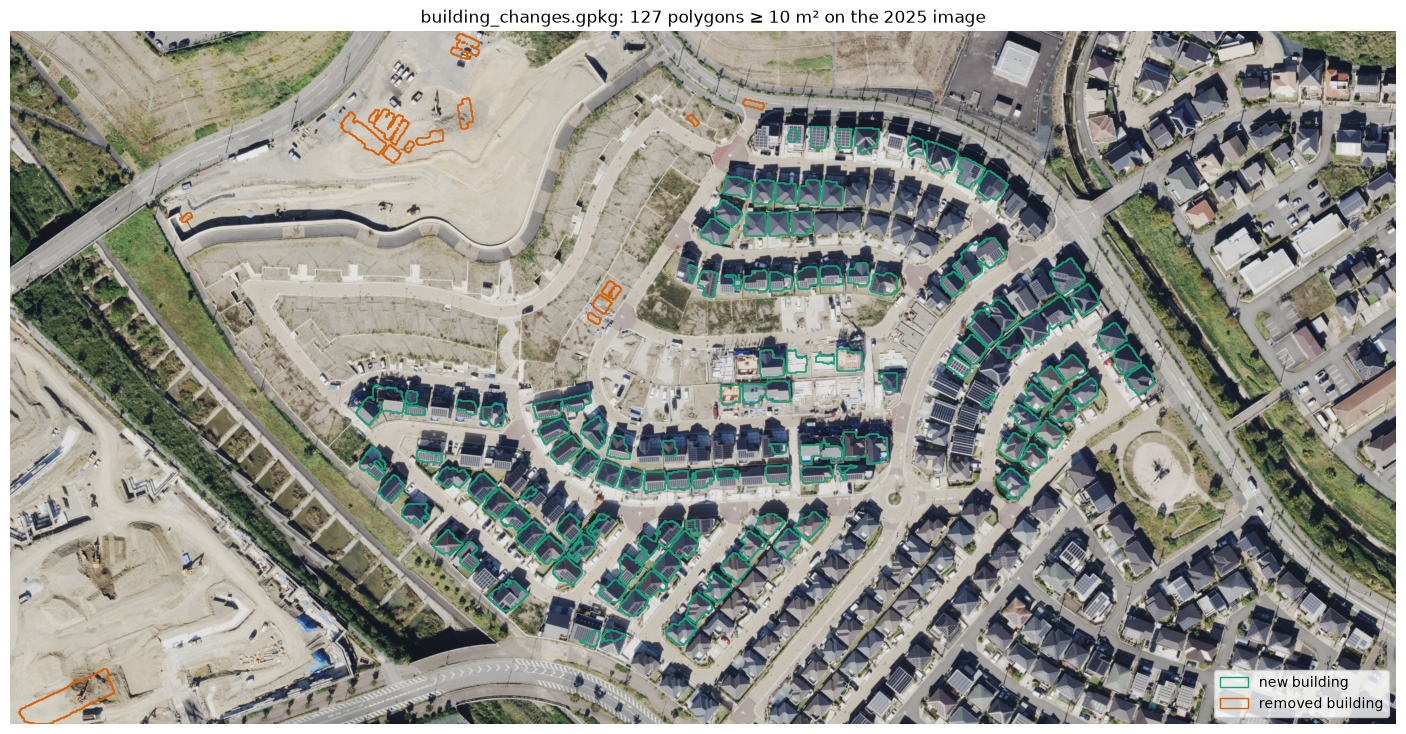

In [10]:
extent = [transform.c, transform.c + transform.a * t1.shape[1],
          transform.f + transform.e * t1.shape[0], transform.f]

fig, ax = plt.subplots(figsize=(18, 9))
ax.imshow(images[2025], extent=extent)
colours = {"new building": "#1b9e77", "removed building": "#d95f02"}
for change_type_name, group in building_changes.groupby("change_type"):
    group.plot(ax=ax, facecolor="none", edgecolor=colours[change_type_name], linewidth=1.2)
ax.legend(handles=[Patch(edgecolor=c, facecolor="none", label=n) for n, c in colours.items()], loc="lower right")
ax.set_title(f"building_changes.gpkg: {len(building_changes)} polygons ≥ {MIN_AREA_M2} m² on the 2025 image")
ax.set_axis_off()
plt.show()

The polygons line up with the imagery because both use the same CRS; `extent` places the image in map coordinates. This file can be opened directly in QGIS or ArcGIS, joined with parcel or address data, or summarised per district. To browse the saved rasters interactively in the notebook, `geoai.view_raster(str(OUT_DIR / "change_map.tif"), nodata=0, cmap="Reds", basemap=str(rgb_paths[2025]))` opens a zoomable map; it appears when you run the page yourself.

```{tip}
For a quick one-off analysis, `geoai.change_detection.changestar_detect(image1, image2, model_name=..., output_change=...)` initialises the model, runs `predict()` and returns the same result dictionary in a single call. Use the `ChangeStarDetection` class, as on these pages, when you want to reuse one detector for several image pairs or use its plotting functions.
```

---

## 4. Python reactivation

- `zip(axes, thresholds)` pairs two sequences so you can loop over both together, a pattern useful whenever you process two related lists in lockstep.
- `np.linspace(0.05, 0.95, 19)` creates 19 evenly spaced values, convenient for testing a parameter across its range.
- A list comprehension such as `[{"change_type": ..., "geometry": ...} for geom, value in shapes(...)]` builds a list of dictionaries, which `gpd.GeoDataFrame(records, crs=crs)` turns directly into a table with geometries.
- `gdf.groupby("change_type")["area_m2"].agg(["count", "sum", "median"])` summarises one column per group in a single step.
- `Path.iterdir()` lists a folder's contents, and `f.stat().st_size` gives each file's size in bytes, useful for confirming that outputs were saved.

---

## 5. Common pitfalls

- **Treating the default threshold of 0.5 as universally correct.** The right value depends on whether false alarms or missed changes are more costly for your application; plot the area-threshold curve to see how sensitive your result is.
- **Re-running a model just to try a new threshold.** The {term}`probability map <Probability Map>` already contains everything; thresholding it is instantaneous.
- **Committing to one model variant without comparing at least one alternative.** The S1 and S9 variants answer different questions; their disagreement is informative, not just noise.
- **Skipping the baseline.** Without it, you cannot tell how much a deep learning model actually adds for your data.
- **Exporting raw polygons without attributes or a minimum area.** A GeoPackage full of unlabeled fragments is hard to use; add the change type and area, and remove fragments below a documented minimum size.
- **Computing areas in a geographic CRS.** Polygon areas are only meaningful in a projected CRS with metre units; reproject first if your data use latitude and longitude.

---

## 6. Mini task

Looking at the three-threshold comparison in step B, would you expect the number of changed pixels at `threshold=0.3` to be larger or smaller than at `threshold=0.7`? Explain using the sensitivity/specificity framing from this page. Then check the area-threshold curve: is the difference as large as you expected, and why?

:::{dropdown} Sample solution
:class: note

The number of changed pixels at `threshold=0.3` is larger: a lower threshold lets more pixels with moderate change probability count as changed, increasing sensitivity at the cost of including more likely false alarms. At `threshold=0.7`, only pixels with high change probability pass, reducing the count but increasing confidence in each remaining detection.

On this image pair, the threshold of 0.3 flags roughly 30% more area than 0.7: a clear difference, but far from the doubling you might expect from such different thresholds. ChangeStar's probabilities are concentrated close to 0 and 1 (see the histogram on the previous page), so only the relatively few pixels with intermediate probabilities, mostly building edges and some uncertain houses, switch between the two maps. A model with less decisive probabilities would produce a steeper curve, and the threshold would matter even more.
:::

---

## 7. Key takeaways

- The change map is just `change_prob > threshold`; test thresholds on the saved probabilities and plot the changed area against the threshold to judge how sensitive your result is.
- Model variants can answer different questions: S1 detects building change, S9 land-cover change. Compare at least one alternative and choose by your project question.
- A simple pixel-wise baseline on the same images shows what the deep learning model adds: compact, object-shaped detections instead of speckled pixel noise.
- Combining the change map with the per-date masks, vectorizing, and removing fragments produces an attributed GeoPackage that a GIS can actually use.
- The next page trains a change detection model from labeled image pairs, which also lets you tune the threshold against reference data instead of by eye.

### Further reading

- OpenGeoAI, ["ChangeStar"](https://opengeoai.org/examples/changestar/) — the example notebook with the variant comparison and threshold steps adapted here.
- Xia et al. (2023), ["OpenEarthMap: A Benchmark Dataset for Global High-Resolution Land Cover Mapping"](https://arxiv.org/abs/2210.10732) — the land-cover scheme behind the S9 variant's nine classes.